# Step 8 — 2D Burgers' Equation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/step08_burgers_2d.ipynb)

*The "12 steps to Navier-Stokes" with sesmax (after Lorena Barba's CFD Python), moved from somax's tutorial series.*

The 2D viscous Burgers equation combines nonlinear convection (Step 6) with diffusion (Step 7).

**What you will learn:**

1. How viscosity balances nonlinear steepening
2. The effect of low vs. high viscosity on the solution
3. Differentiating through the viscosity for parameter sensitivity
4. Why Burgers is the gateway to Navier–Stokes

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## The PDE

$$
\frac{\partial u}{\partial t} + u \frac{\partial u}{\partial x} + v \frac{\partial u}{\partial y} = \nu \left( \frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2} \right)
$$

$$
\frac{\partial v}{\partial t} + u \frac{\partial v}{\partial x} + v \frac{\partial v}{\partial y} = \nu \left( \frac{\partial^2 v}{\partial x^2} + \frac{\partial^2 v}{\partial y^2} \right)
$$

Burgers' equation is the simplest PDE that contains both nonlinear advection and diffusion — the same two ingredients that appear in the Navier–Stokes momentum equation. Low viscosity allows steep gradients (near-shocks); high viscosity smooths everything out. The balance between these two effects determines the solution character and is controlled by the Reynolds number $\mathrm{Re} = U \ell / \nu$.

### Symbols

The page uses the classic CFD letters. Everything is nondimensional, and $x$ and $y$ are the spatial coordinates (there is no inference state on this page).

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $x \in [0, L_x)$, $y \in [0, L_y)$ | spatial coordinates | $\mathbb{R}$ |
| $t \in [t_0, t_1]$ | time | $\mathbb{R}$ |
| $u(x, y, t)$, $v(x, y, t)$ | velocity components along $x$ and $y$ | $\mathbb{R}$ |
| $\nu$ | viscosity, the model's differentiable parameter | $\mathbb{R}_{>0}$ |
| $\mathrm{Re} = U \ell / \nu$ | Reynolds number, with characteristic speed $U$ and length $\ell$ | $\mathbb{R}_{>0}$ |
| $L_x$, $L_y$ | domain lengths | $\mathbb{R}_{>0}$ |
| $N_{\Omega_x,x}$, $N_{\Omega_x,y}$ | number of interior grid cells along $x$ and $y$ | count |
| $\Delta x$, $\Delta y$, $\Delta t$ | grid spacings and time step | $\mathbb{R}_{>0}$ |
| $u_{j,i}$, $v_{j,i}$ | the fields in row $j$ and column $i$; with ghosts, $j = 0, \dots, N_{\Omega_x,y} + 1$ and $i = 0, \dots, N_{\Omega_x,x} + 1$ | $\mathbb{R}$ |
| $f_{j,i}$ | either field, in the boundary conditions below | $\mathbb{R}$ |
| $\mu_0$, $\sigma_0$ | centre and width of the initial Gaussian | $\mathbb{R}$, $\mathbb{R}_{>0}$ |
| $\mathcal{L}$ | loss, minimised | $\mathbb{R}$ |
| $N_T$ | number of saved snapshots | count |

## Grid layout and boundary conditions

In 2D, sesmax uses the **Arakawa C-grid** from finitevolX, where different variables live at different positions within each cell $(j, i)$:

| Point | Position | Holds |
| --- | --- | --- |
| T-point | cell centre | scalars such as $u$ and $v$ |
| U-point | east and west faces, $i \pm 1/2$ | $x$-fluxes |
| V-point | north and south faces, $j \pm 1/2$ | $y$-fluxes |
| X-point | corners | vorticity (in some formulations) |

The full array has $N_{\Omega_x,y} + 2$ rows and $N_{\Omega_x,x} + 2$ columns: a **1-cell ghost ring** surrounds the $N_{\Omega_x,y} \times N_{\Omega_x,x}$ interior cells. Row $0$ and row $N_{\Omega_x,y} + 1$ are the south and north ghosts, and column $0$ and column $N_{\Omega_x,x} + 1$ are the west and east ghosts. The interior cells are `[1:-1, 1:-1]`. The ghost cells are filled by the boundary conditions before each evaluation of the right-hand side.

**Periodic BCs** (`enforce_periodic`) copy the last interior row or column into the opposite ghost row or column. Both $u$ and $v$ receive the same treatment, written here for a field $f$:

- South ghost row: $f_{0,i} = f_{N_{\Omega_x,y},i}$
- North ghost row: $f_{N_{\Omega_x,y} + 1,i} = f_{1,i}$
- West ghost column: $f_{j,0} = f_{j,N_{\Omega_x,x}}$
- East ghost column: $f_{j,N_{\Omega_x,x} + 1} = f_{j,1}$

In [2]:
import diffrax as dfx
import equinox as eqx
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Create the model

`Burgers2D.create()` builds a model on a 2D Arakawa C-grid with `nx` by `ny` interior cells spanning a domain of size `Lx` by `Ly`. The viscosity `nu` is a differentiable parameter visible to `eqx.filter_grad`.

In [4]:
# Shapes: N_Ωx,x = 64, N_Ωx,y = 64 interior cells

num_cells_x = 64
num_cells_y = 64
length_x = 2.0
length_y = 2.0
viscosity = 0.05

# today (sesmax_core)
model = sxt.Burgers2D.create(
    nx=num_cells_x, ny=num_cells_y, Lx=length_x, Ly=length_y, nu=viscosity
)

print(model)
print(f"Grid: Nx={model.grid.Nx}, Ny={model.grid.Ny}")
print(f"Spacing: dx={model.grid.dx:.4f}, dy={model.grid.dy:.4f}")

Burgers2D(
  params=Burgers2DParams(nu=weak_f32[]),
  grid=CartesianGrid2D(Nx=66, Ny=66, Lx=2.0, Ly=2.0, dx=0.03125, dy=0.03125),
  diff=Difference2D(
    grid=CartesianGrid2D(Nx=66, Ny=66, Lx=2.0, Ly=2.0, dx=0.03125, dy=0.03125)
  ),
  advection=Advection2D(
    grid=CartesianGrid2D(Nx=66, Ny=66, Lx=2.0, Ly=2.0, dx=0.03125, dy=0.03125),
    mask=None,
    recon=Reconstruction2D(
      grid=CartesianGrid2D(Nx=66, Ny=66, Lx=2.0, Ly=2.0, dx=0.03125, dy=0.03125)
    ),
    _mask_hierarchy_x=None,
    _mask_hierarchy_y=None
  ),
  interp=Interpolation2D(
    grid=CartesianGrid2D(Nx=66, Ny=66, Lx=2.0, Ly=2.0, dx=0.03125, dy=0.03125)
  ),
  mask=None
)
Grid: Nx=66, Ny=66
Spacing: dx=0.0312, dy=0.0312


## 2. Initial condition

A 2D Gaussian with centre $\mu_0 = 1$ and width $\sigma_0 = 0.2$ in both coordinates serves for both velocity components,

$$
u_0(x, y) = v_0(x, y) = \exp\left(-\frac{(x - \mu_0)^2 + (y - \mu_0)^2}{2 \sigma_0^2}\right)
$$

In [5]:
# Shapes: N_Ωx,x = 64, N_Ωx,y = 64 interior cells;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

inner = slice(1, -1)
interior = (inner, inner)
bump_centre = 1.0
bump_width = 0.2

# xᵢ = i Δx
x_position = jnp.arange(model.grid.Nx) * model.grid.dx  # → (N_Ωx,x + 2,)
# yⱼ = j Δy
y_position = jnp.arange(model.grid.Ny) * model.grid.dy  # → (N_Ωx,y + 2,)
x_grid, y_grid = jnp.meshgrid(x_position, y_position)  # → G each

# z_x = (x − μ₀) / σ₀
standardised_x = (x_grid - bump_centre) / bump_width  # → G
# z_y = (y − μ₀) / σ₀
standardised_y = (y_grid - bump_centre) / bump_width  # → G
# r² = z_x² + z_y²
radius_squared = standardised_x**2 + standardised_y**2  # → G
# u₀ = v₀ = exp(−r² / 2)
gaussian = jnp.exp(-0.5 * radius_squared)  # → G
initial_u = gaussian  # → G
initial_v = gaussian  # → G

# today (sesmax_core)
initial_state = sxt.Burgers2DState(u=initial_u, v=initial_v)

print(f"State shapes: u={initial_state.u.shape}, v={initial_state.v.shape}")

State shapes: u=(66, 66), v=(66, 66)


## 3. Run the simulation

We integrate from $t_0 = 0$ to $t_1 = 0.5$ with `model.integrate()`, saving a snapshot at every time step.

In [6]:
# Shapes: N_T = 250 saved snapshots;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) = 66 × 66 with the ghosts

time_step = 0.002
end_time = 0.5

# tₖ = k Δt, k = 0, …, N_T − 1
save_times = jnp.arange(0.0, end_time, time_step)  # → (N_T,)

# today (sesmax_core, diffrax)
# (u, v)(x, y, tₖ) for each saved time
solution = model.integrate(  # u, v → N_T × G
    initial_state,
    t0=0.0,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=save_times),
)

print(f"Solution shapes: u={solution.ys.u.shape}, v={solution.ys.v.shape}")

Solution shapes: u=(250, 66, 66), v=(250, 66, 66)


## 4. Visualize initial and final fields

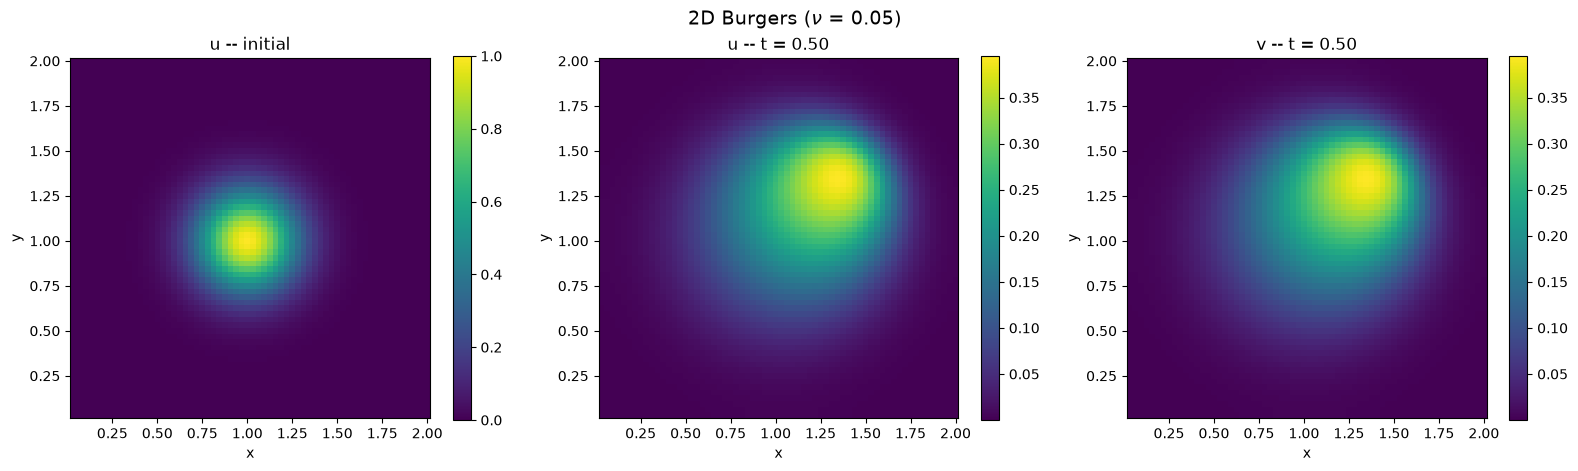

In [7]:
final_time = float(save_times[-1])
panels = [
    (solution.ys.u[0], "u -- initial"),
    (solution.ys.u[-1], f"u -- t = {final_time:.2f}"),
    (solution.ys.v[-1], f"v -- t = {final_time:.2f}"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (field, title) in zip(axes, panels, strict=True):
    mesh = ax.pcolormesh(
        x_grid[interior],
        y_grid[interior],
        field[interior],
        shading="auto",
        cmap="viridis",
    )
    plt.colorbar(mesh, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")

plt.suptitle(r"2D Burgers ($\nu$ = 0.05)", fontsize=14)
plt.tight_layout()
plt.show()

## 5. Low vs. high viscosity

We run two simulations with different viscosities from the same initial condition and compare the final fields.

In [8]:
# Shapes: N_Ωx,x = 64, N_Ωx,y = 64 interior cells; N_T = 1 saved snapshot;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

low_viscosity = 0.01
high_viscosity = 0.2

# today (sesmax_core)
model_low = sxt.Burgers2D.create(
    nx=num_cells_x, ny=num_cells_y, Lx=length_x, Ly=length_y, nu=low_viscosity
)
# today (sesmax_core)
model_high = sxt.Burgers2D.create(
    nx=num_cells_x, ny=num_cells_y, Lx=length_x, Ly=length_y, nu=high_viscosity
)

# today (sesmax_core, diffrax)
# (u, v)(x, y, t₁; ν) for ν = 0.01
solution_low = model_low.integrate(  # u, v → N_T × G
    initial_state,
    t0=0.0,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(t1=True),
)
# today (sesmax_core, diffrax)
# (u, v)(x, y, t₁; ν) for ν = 0.2
solution_high = model_high.integrate(  # u, v → N_T × G
    initial_state,
    t0=0.0,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(t1=True),
)

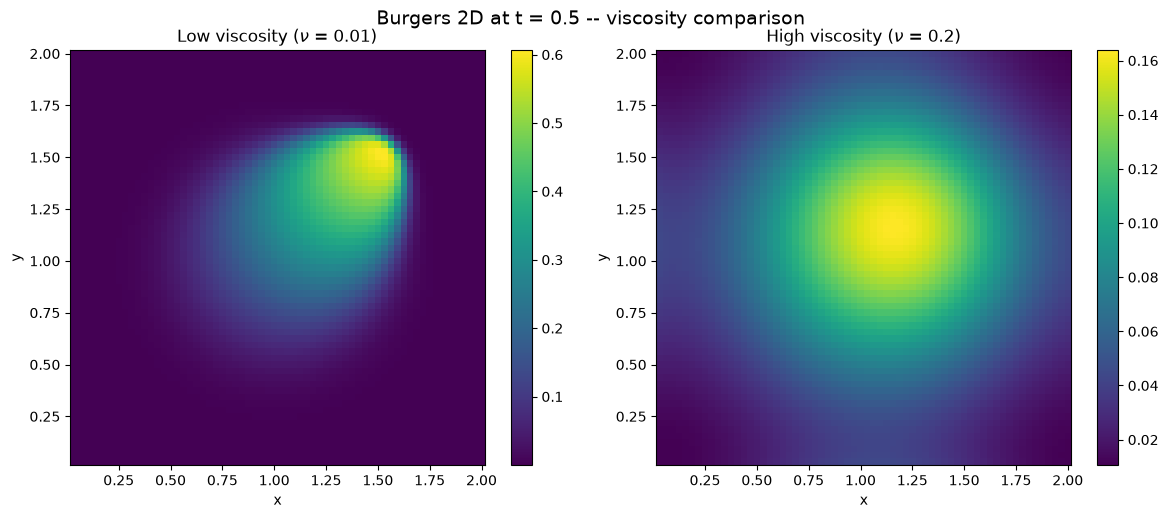

In [9]:
panels = [
    (solution_low.ys.u[0], rf"Low viscosity ($\nu$ = {low_viscosity})"),
    (solution_high.ys.u[0], rf"High viscosity ($\nu$ = {high_viscosity})"),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (field, title) in zip(axes, panels, strict=True):
    mesh = ax.pcolormesh(
        x_grid[interior],
        y_grid[interior],
        field[interior],
        shading="auto",
        cmap="viridis",
    )
    plt.colorbar(mesh, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")

plt.suptitle(f"Burgers 2D at t = {end_time} -- viscosity comparison", fontsize=14)
plt.tight_layout()
plt.show()

Low viscosity preserves sharper gradients (the nonlinear steepening from Step 6 dominates). High viscosity smears the solution out (the diffusion from Step 7 dominates).

## 6. Cross-section comparison

We compare the profile $u(x, y_\text{mid}, t_1)$ along the middle row of the grid for the two viscosities.

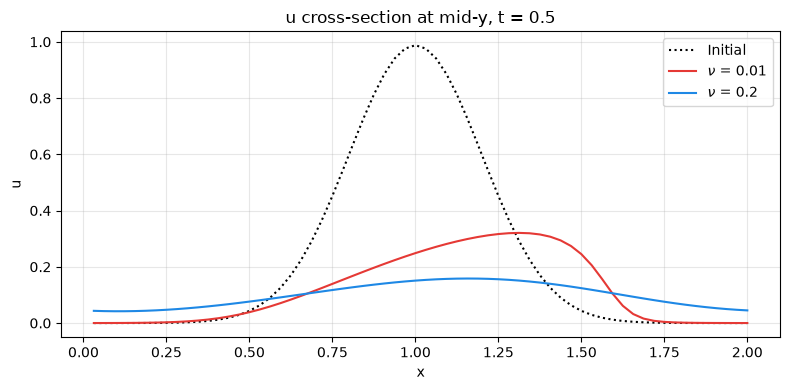

In [10]:
# Shapes: N_Ωx,x = 64 interior columns; arrays carry N_Ωx,x + 2 = 66 with the ghosts

mid_row = model.grid.Ny // 2

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    x_position[inner],
    initial_u[mid_row, inner],
    label="Initial",
    lw=1.5,
    color="black",
    ls=":",
)
ax.plot(
    x_position[inner],
    solution_low.ys.u[0, mid_row, inner],
    label=rf"$\nu$ = {low_viscosity}",
    lw=1.5,
    color="#E53935",
)
ax.plot(
    x_position[inner],
    solution_high.ys.u[0, mid_row, inner],
    label=rf"$\nu$ = {high_viscosity}",
    lw=1.5,
    color="#1E88E5",
)
ax.set_xlabel("x")
ax.set_ylabel("u")
ax.set_title(f"u cross-section at mid-y, t = {end_time}")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Gradient through viscosity

We compute $\partial \mathcal{L} / \partial \nu$ for the loss

$$
\mathcal{L}(\nu) = \sum_{j=0}^{N_{\Omega_x,y} + 1} \sum_{i=0}^{N_{\Omega_x,x} + 1} \left( u_{j,i}(t_1; \nu)^2 + v_{j,i}(t_1; \nu)^2 \right)
$$

summed over every cell including the ghosts, with $t_1 = 0.3$. It is proportional to the kinetic energy, so the gradient tells us how the energy depends on viscosity — useful for calibrating sub-grid diffusion.

In [11]:
# Shapes: N_T = 1 saved snapshot;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) = 66 × 66 with the ghosts


# today (equinox)
@eqx.filter_grad
def grad_wrt_model(model):
    """Gradient of the loss ℒ(ν) = Σ (u² + v²) with respect to the model."""
    # today (sesmax_core, diffrax)
    # (u, v)(x, y, t₁; ν)
    final_solution = model.integrate(initial_state, t0=0.0, t1=0.3, dt=0.002)
    final_u = final_solution.ys.u  # → N_T × G
    final_v = final_solution.ys.v  # → N_T × G
    # u² + v²
    speed_squared = final_u**2 + final_v**2  # → N_T × G
    # ℒ(ν) = Σⱼᵢ (uⱼᵢ² + vⱼᵢ²)
    loss = jnp.sum(speed_squared)  # → ()
    return loss


# ∂ℒ/∂ν
model_grads = grad_wrt_model(model)

print("--- Gradient w.r.t. viscosity ---")
print(f"  dL/d(nu) = {model_grads.params.nu:.6f}")

--- Gradient w.r.t. viscosity ---


  dL/d(nu) = -1006.128052


## 8. Joint gradient — viscosity and initial state

We differentiate the same loss with respect to the viscosity $\nu$ and the initial condition $(u_0, v_0)$ at once.

In [12]:
# Shapes: N_T = 1 saved snapshot;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) = 66 × 66 with the ghosts


def loss_joint(state, model):
    # today (sesmax_core, diffrax)
    # (u, v)(x, y, t₁; u₀, v₀, ν)
    final_solution = model.integrate(state, t0=0.0, t1=0.3, dt=0.002)
    final_u = final_solution.ys.u  # → N_T × G
    final_v = final_solution.ys.v  # → N_T × G
    # u² + v²
    speed_squared = final_u**2 + final_v**2  # → N_T × G
    # ℒ(u₀, v₀, ν) = Σⱼᵢ (uⱼᵢ² + vⱼᵢ²)
    loss = jnp.sum(speed_squared)  # → ()
    return loss


def loss_joint_of_pair(pair):
    return loss_joint(*pair)


# filter_grad differentiates only the floating-point leaves: the grid's
# integer sizes are leaves too, and jax.grad would refuse them.
# today (equinox)
# (∂ℒ/∂(u₀, v₀), ∂ℒ/∂ν)
state_grads, model_grads = eqx.filter_grad(loss_joint_of_pair)((initial_state, model))
# maxⱼᵢ |∂ℒ/∂u₀,ⱼᵢ|
max_u_grad = jnp.max(jnp.abs(state_grads.u))  # G → ()
# maxⱼᵢ |∂ℒ/∂v₀,ⱼᵢ|
max_v_grad = jnp.max(jnp.abs(state_grads.v))  # G → ()

print("--- Joint gradient ---")
print(f"  max |dL/du0| = {float(max_u_grad):.6f}")
print(f"  max |dL/dv0| = {float(max_v_grad):.6f}")
print(f"  dL/d(nu)     = {model_grads.params.nu:.6f}")

--- Joint gradient ---
  max |dL/du0| = 0.735805
  max |dL/dv0| = 0.735805
  dL/d(nu)     = -1006.128052


## Summary

| Concept | API |
|---------|-----|
| Create model | `Burgers2D.create(nx=64, ny=64, Lx=2.0, Ly=2.0, nu=0.05)` |
| Two-component state | `Burgers2DState(u=initial_u, v=initial_v)` |
| Viscosity comparison | create two models with different `nu` |
| Grad w.r.t. $\nu$ | `eqx.filter_grad(loss)(model)` |
| Joint grad | `eqx.filter_grad(loss_of_pair)((initial_state, model))` |

**Where we stand:** Steps 5–8 have covered the fundamental building blocks of fluid dynamics in 2D: linear advection, nonlinear advection, diffusion, and their combination in Burgers' equation. The next steps introduce **elliptic solvers** (Laplace, Poisson) which are needed to enforce incompressibility in the Navier–Stokes equations.